In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/tips.csv")

In [2]:
display(df.head())
print(df.shape)
df.info()
display(df.describe())
display(df.isna().sum())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


(244, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [3]:
df["tip_pct"] = df["tip"] / df["total_bill"] * 100
df["tip_pct"].describe().round(2)

count    244.00
mean      16.08
std        6.11
min        3.56
25%       12.91
50%       15.48
75%       19.15
max       71.03
Name: tip_pct, dtype: float64

In [4]:
by_day = df.groupby("day").agg(
    visits=("total_bill", "count"),
    revenue=("total_bill", "sum"),
    avg_bill=("total_bill", "mean"),
    avg_tip_pct=("tip_pct", "mean"),
).round(2).sort_values("revenue", ascending=False)
by_day

,visits,revenue,avg_bill,avg_tip_pct
day,,,,
Sat,87,1778.40,20.44,15.32
Sun,76,1627.16,21.41,16.69
Thur,62,1096.33,17.68,16.13
Fri,19,325.88,17.15,16.99


In [5]:
df.groupby("size")["tip_pct"].agg(["count", "mean"]).round(2)

,count,mean
size,,
1,4,21.73
2,156,16.57
3,38,15.22
4,37,14.59
5,5,14.15
6,4,15.62


In [6]:
df.groupby(["time", "smoker"])["tip_pct"].mean().round(2)

time    smoker
Dinner  No        15.87
        Yes       16.08
Lunch   No        16.09
        Yes       17.04
Name: tip_pct, dtype: float64

In [7]:
display(df.sort_values("tip_pct", ascending=False).head(5))
big = df[df["tip_pct"] > 25]
print(len(big))

,total_bill,tip,sex,smoker,day,time,size,tip_pct
172,7.25,5.15,Male,Yes,Sun,Dinner,2,71.034483
178,9.60,4.00,Female,Yes,Sun,Dinner,2,41.666667
67,3.07,1.00,Female,Yes,Sat,Dinner,1,32.573290
232,11.61,3.39,Male,No,Sat,Dinner,2,29.198966
183,23.17,6.50,Male,Yes,Sun,Dinner,4,28.053517


10


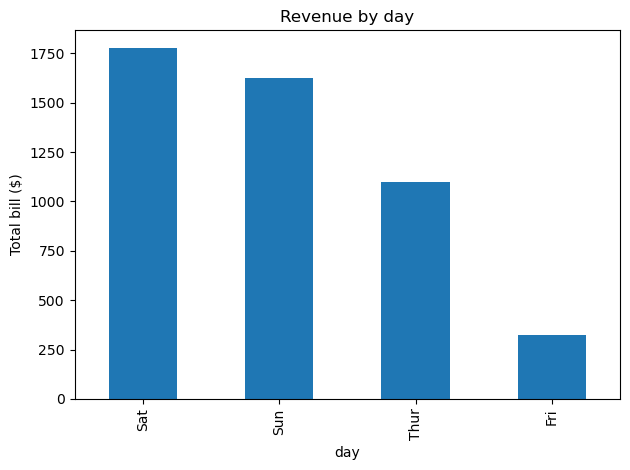

In [9]:
by_day["revenue"].plot(kind="bar", title="Revenue by day")
plt.ylabel("Total bill ($)")
plt.tight_layout()
plt.savefig("outputs/revenue_by_day.png")
plt.show()